# LeetCode #1109: Corporate Flight Bookings

https://leetcode.com/problems/corporate-flight-bookings/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n \cdot m)$ | $O(1)$ |
| **Optimal: Difference Array ★** | $O(n + m)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
For each booking (first, last, seats), loop over every flight index in [first, last] and add `seats` to the answer array. With n flights and m bookings this is $O(n \cdot m)$ — too slow when both are large.

### Optimal: Difference Array ★
Use a difference array `diff` of size n+1. For each booking: `diff[first-1] += seats` and `diff[last] -= seats`. A single prefix-sum pass converts `diff` into the final seat counts in $O(n)$.

**Why this is better than Brute Force:** Each booking touches only 2 array positions instead of up to n; the $O(n)$ prefix-sum pass then "spreads" all bookings at once, giving $O(n + m)$ total instead of $O(n \cdot m)$.

**Constraints:**
* 1 <= n <= 20000
* 1 <= bookings.length <= 20000
* bookings[i].length == 3
* 1 <= first <= last <= n
* 1 <= seats <= 10000

## Solutions

### C#

In [ ]:
public class Solution {
    public int[] CorpFlightBookings(int[][] bookings, int n) {
        // Difference array: mark the start (+seats) and one past the end (-seats) of each booking
        int[] diff = new int[n + 1];
        foreach (var b in bookings) {
            int first = b[0], last = b[1], seats = b[2];
            diff[first - 1] += seats;   // booking begins at flight first (0-indexed: first-1)
            diff[last] -= seats;         // booking ends after flight last
        }
        // Prefix sum converts the difference array into actual seat counts per flight
        int[] ans = new int[n];
        int running = 0;
        for (int i = 0; i < n; i++) {
            running += diff[i];
            ans[i] = running;
        }
        return ans;
    }
}

### Python

In [ ]:
class Solution:
    def corpFlightBookings(self, bookings: list[list[int]], n: int) -> list[int]:
        # Difference array: mark the start (+seats) and one past the end (-seats) of each booking
        diff = [0] * (n + 1)
        for first, last, seats in bookings:
            diff[first - 1] += seats   # booking begins at flight first (0-indexed: first-1)
            diff[last] -= seats         # booking ends after flight last

        # Prefix sum converts the difference array into actual seat counts per flight
        ans = []
        running = 0
        for i in range(n):
            running += diff[i]
            ans.append(running)
        return ans

### Go

In [ ]:
func corpFlightBookings(bookings [][]int, n int) []int {
    // Difference array: mark the start (+seats) and one past the end (-seats) of each booking
    diff := make([]int, n+1)
    for _, b := range bookings {
        first, last, seats := b[0], b[1], b[2]
        diff[first-1] += seats // booking begins at flight first (0-indexed: first-1)
        diff[last] -= seats     // booking ends after flight last
    }
    // Prefix sum converts the difference array into actual seat counts per flight
    ans := make([]int, n)
    running := 0
    for i := 0; i < n; i++ {
        running += diff[i]
        ans[i] = running
    }
    return ans
}

### Rust

In [ ]:
impl Solution {
    pub fn corp_flight_bookings(bookings: Vec<Vec<i32>>, n: i32) -> Vec<i32> {
        let n = n as usize;
        // Difference array: mark the start (+seats) and one past the end (-seats) of each booking
        let mut diff = vec![0i32; n + 1];
        for b in &bookings {
            let (first, last, seats) = (b[0] as usize, b[1] as usize, b[2]);
            diff[first - 1] += seats; // booking begins at flight first (0-indexed: first-1)
            diff[last] -= seats;       // booking ends after flight last
        }
        // Prefix sum converts the difference array into actual seat counts per flight
        let mut ans = vec![0i32; n];
        let mut running = 0i32;
        for i in 0..n {
            running += diff[i];
            ans[i] = running;
        }
        ans
    }
}

## Example Scenarios

### 1. Common Case — Three Overlapping Bookings
**Input:** `bookings = [[1,2,10],[2,3,20],[2,5,25]]`, `n = 5`

Each booking writes two entries: $diff[0] \mathrel{+}= 10$, $diff[2] \mathrel{-}= 10$; $diff[1] \mathrel{+}= 20$, $diff[3] \mathrel{-}= 20$; $diff[1] \mathrel{+}= 25$, $diff[5] \mathrel{-}= 25$. That leaves $diff = [10, 45, -10, -20, 0, -25]$, and the prefix sum gives **[10, 55, 45, 25, 25]**. Flight 2 is the busiest because all three bookings cover it.

### 2. Slightly Complex — Nested and Disjoint Bookings Together
**Input:** `bookings = [[1,8,5],[2,4,3],[6,8,7],[3,3,100]]`, `n = 8`

One booking spans everything, one is nested inside it, one sits at the far end, and one covers a single flight. $diff = [5, 3, 100, -100, -3, 7, 0, 0, -12]$ and the prefix sum is **[5, 8, 108, 8, 5, 12, 12, 12]**. The spike at flight 3 comes from the single-flight booking, which contributes $+100$ at index 2 and $-100$ at index 3 — adjacent entries that cancel immediately.

### 3. Edge Case: Time Factor — Every Booking Spans Every Flight
**Input:** 20000 bookings of `[1, 20000, 1]`, `n = 20000`

The brute force would write $20000 \times 20000 = 4 \times 10^8$ cells; the difference array writes $2 \times 20000 = 40000$ entries and then makes one 20000-step pass — about $10^4$ times less work. Note the asymmetry: a long booking costs the difference array exactly the same two writes as a one-flight booking.

### 4. Edge Case: Space Factor — The n+1 Guard Slot
**Input:** `bookings = [[1,5,1]]`, `n = 5`

$diff$ is allocated with $n + 1 = 6$ slots precisely so that a booking ending at the last flight can write $diff[5] \mathrel{-}= 1$ without going out of bounds. The prefix-sum loop only reads indices $0 \ldots n-1$, so that final entry is written and never read. Output **[1, 1, 1, 1, 1]**. Auxiliary space is $n+1$ integers plus the $n$-element answer, i.e. $O(n)$.

### 5. Almost-Impossible but Plausible — One Booking at Every Maximum
**Input:** `bookings = [[1, 20000, 10000]]`, `n = 20000`

A single booking at the largest allowed seat count covering every flight. Every entry of the answer is 10000, and the running total never exceeds $10^4$. Pushed further, the true ceiling is $20000$ bookings $\times\ 10000$ seats $= 2 \times 10^8$ on one flight — still inside 32-bit signed range (max $\approx 2.15 \times 10^9$), so no 64-bit accumulator is needed.

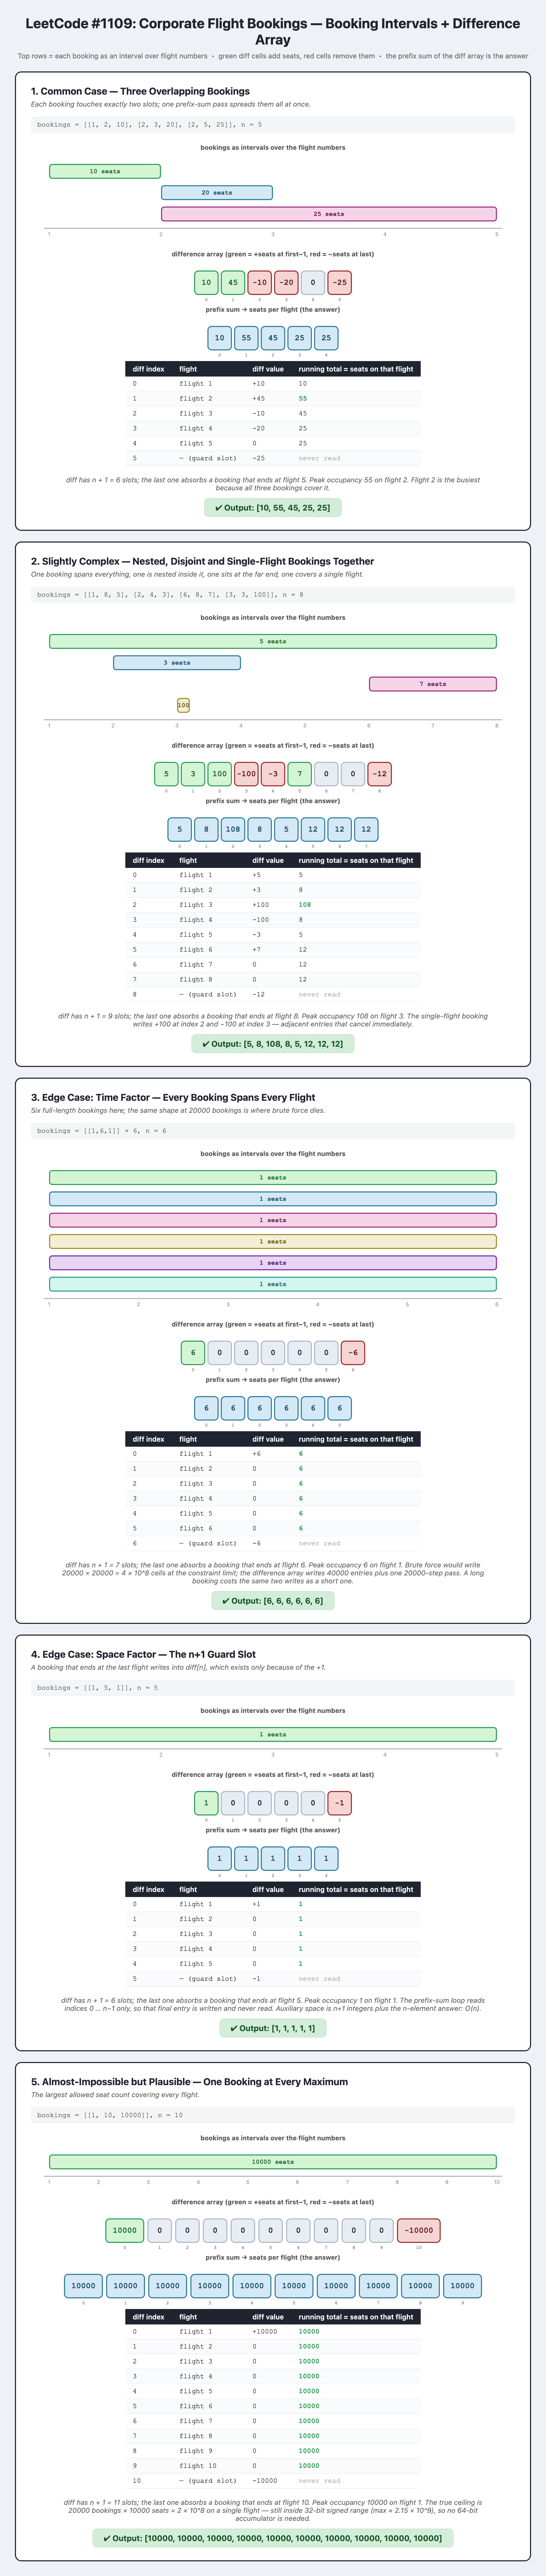